# Mouse smc: cell-type annotation (stage 04c)

Every cluster of the re-integrated smc lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_smc.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_smc.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "smc", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_smc.h5ad"
TABLE = REPO / "resources/annotations/mouse_smc.csv"
PANEL = ['Acta2', 'Myh11', 'Tagln', 'Des', 'Cnn1', 'Cdh1', 'Pdgfra', 'Pecam1', 'Ptprc', 'Sox6']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,smooth_muscle_cell,48,leiden_scVI_3.0,"Acta2 0.65; Myh11 0.88; Tagln 0.33; Des 0.37 | top vs level: Arhgap6 0.94, Fhl1 0.71, Prune2 0.88"
1,smooth_muscle_cell,90,leiden_scVI_3.0,"Acta2 0.61; Myh11 0.90; Tagln 0.29; Des 0.37 | top vs level: Auts2 0.97, Syndig1 0.87, Adgrl3 0.80"
2,smooth_muscle_cell,66,leiden_scVI_3.0,"Acta2 0.83; Myh11 0.95; Tagln 0.52; Des 0.65 | top vs level: Samd4 0.95, Slc8a1 0.94, Prune2 0.97"
3,smooth_muscle_cell,62,leiden_scVI_3.0,"Acta2 0.73; Myh11 0.90; Tagln 0.27; Des 0.27 | top vs level: Frmd4b 0.87, Crybg3 0.74, Cacna2d1 0.89"
4,EXCLUDE,123,leiden_scVI_3.0,"EXCLUDE: doublet score med 0.12 (level q75 0.72), genes med 997 (level q25 700), 0.42 co-express 2+ lineage panels (level 0.25); panels: smooth_muscle 0.89, endometrial_fibroblasts 0.40, vascular ..."
5,EXCLUDE,67,leiden_scVI_3.0,"EXCLUDE: doublet score med 2.56 (level q75 0.72), genes med 1511 (level q25 700), 0.79 co-express 2+ lineage panels (level 0.25); panels: smooth_muscle 0.94, immune 0.73, vascular 0.24"
6,smooth_muscle_cell,94,leiden_scVI_3.0,"Acta2 0.71; Myh11 0.99; Tagln 0.53; Des 0.35 | top vs level: Adgrl3 0.84, Prkg1 0.99, Cacnb2 0.97"
7,smooth_muscle_cell,40,leiden_scVI_3.0,"Acta2 0.58; Myh11 0.93; Tagln 0.22; Des 0.20 | top vs level: Sema3a 0.75, Astn2 0.62, Zfpm2 0.78"
8,smooth_muscle_cell,58,leiden_scVI_3.0,"Acta2 0.88; Myh11 0.95; Tagln 0.57; Des 0.40 | top vs level: Chrm3 0.55, Schip1 0.84, Dpp6 0.86"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

1769 nuclei; 27 clusters
{'smooth_muscle_cell': 1443, 'EXCLUDE': 326}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

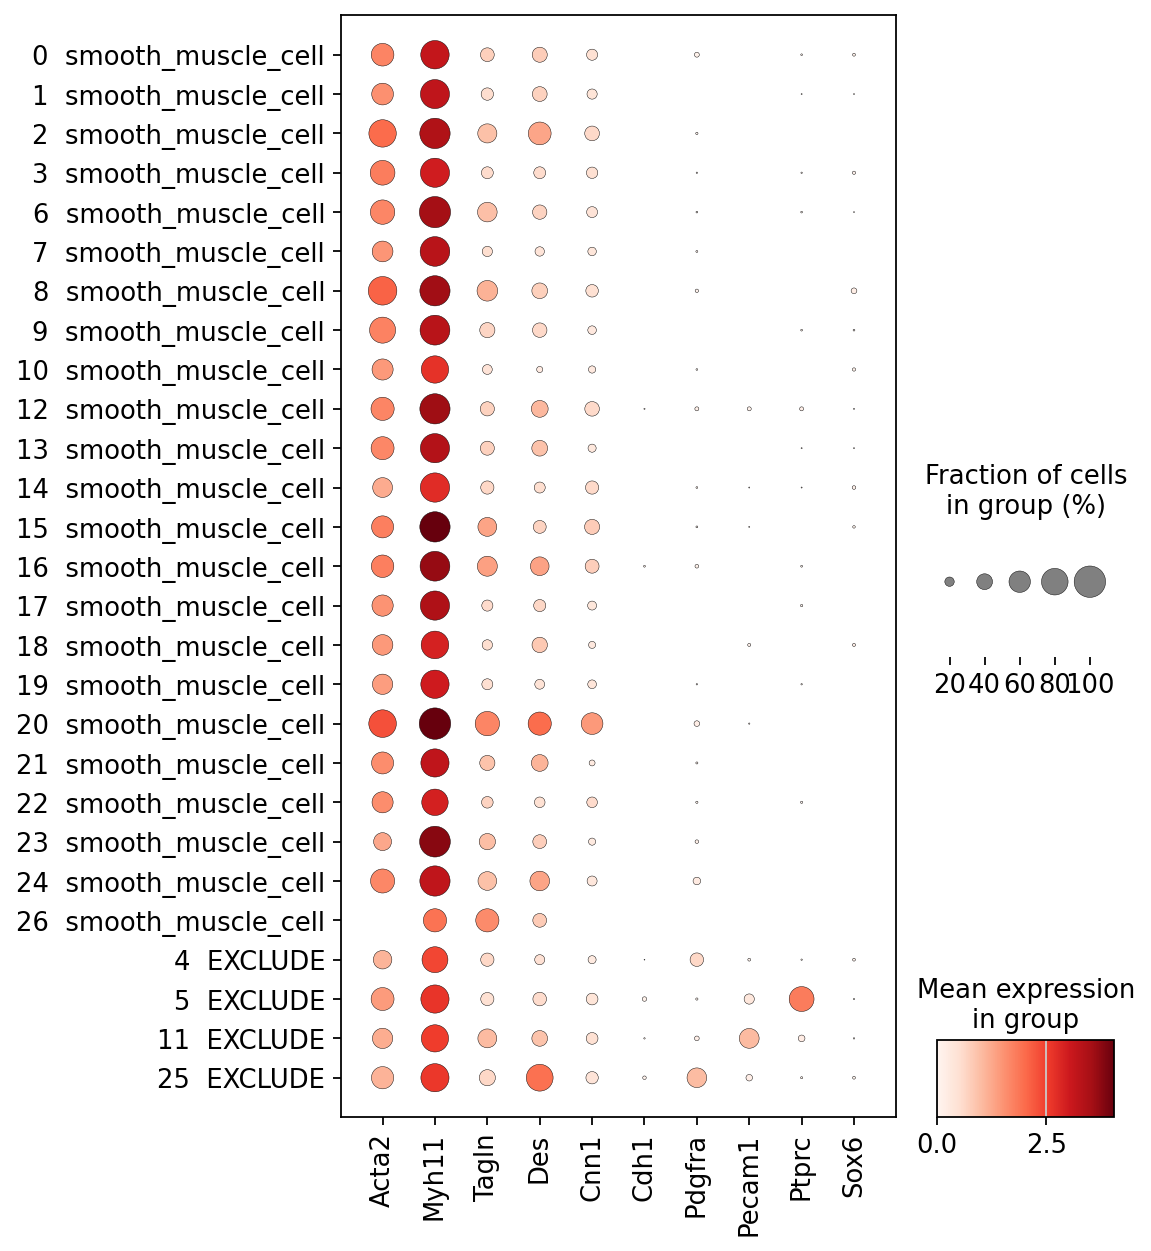

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,48,smooth_muscle_cell,0.03,892.5,1426.5
1,90,smooth_muscle_cell,0.00,1014.0,1693.0
2,66,smooth_muscle_cell,0.07,1454.5,2679.5
3,62,smooth_muscle_cell,0.01,957.0,1544.0
6,94,smooth_muscle_cell,0.07,1394.0,2423.5
7,40,smooth_muscle_cell,0.00,795.0,1101.0
8,58,smooth_muscle_cell,0.07,1499.5,2810.0
9,45,smooth_muscle_cell,0.00,1150.0,1986.0
10,141,smooth_muscle_cell,0.01,926.0,1410.0


## 5. UMAP by cluster and by label

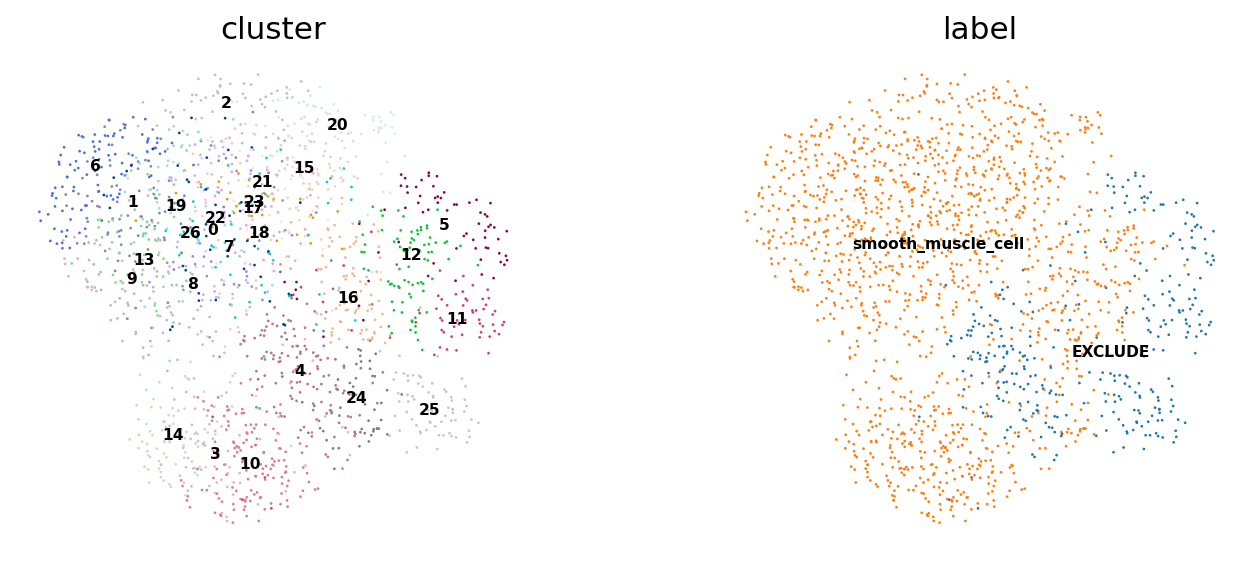

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,Acta2,Myh11,Tagln,Des,Cnn1,Cdh1,Pdgfra,Pecam1,Ptprc,Sox6
4,0.50,0.77,0.32,0.22,0.16,0.01,0.33,0.04,0.02,0.04
5,0.66,0.87,0.31,0.33,0.27,0.07,0.03,0.22,0.73,0.01
11,0.56,0.83,0.51,0.40,0.27,0.02,0.08,0.54,0.13,0.02
25,0.63,0.86,0.41,0.81,0.29,0.05,0.53,0.12,0.03,0.04
lineage,0.64,0.90,0.38,0.37,0.25,0.01,0.08,0.04,0.04,0.02
